# Relationships and groupings in the hotel bookings dataset

**Data source:** Antonio, N., de Almeida, A. and Nunes, L. (2019). *Hotel booking demand datasets*. Data in Brief, 22, 41–49. https://doi.org/10.1016/j.dib.2018.11.126 (file `hotel_bookings_dataset.csv`).
**Date:** 2026-11-05
**Authors:** Group 3, Presentation and Visualization (Infovis2627)
**Description:** This notebook explores how the fields relate to each other (Part 1, task 1.4): bookings and prices over time, cancellations against hotel, lead time, deposit, market segment and country, the market mix of each hotel, the correlation between numeric fields, and the natural groupings of the 32 fields. It uses the **raw** data; where duplicates change a result, both versions are shown.

---

## Contents

1. [Data loading](#1.-Data-loading)
2. [Initial exploration: groupings of the fields](#2.-Initial-exploration:-groupings-of-the-fields)
3. [Cleaning and preparation](#3.-Cleaning-and-preparation)
4. [Analysis: rates and medians by group](#4.-Analysis:-rates-and-medians-by-group)
5. [Accessible visualisation: relationship charts](#5.-Accessible-visualisation:-relationship-charts)
6. [Export](#6.-Export)
7. [Conclusions](#Conclusions)

In [1]:
# ── Imports ──────────────────────────────────────────────────────────────────
import sys
from pathlib import Path

import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

RAW_FILE   = Path('../../Course information/hotel_bookings_dataset.csv')
OUTPUT_DIR = Path('relationships_output')
IMAGES_DIR = Path('../images')
OUTPUT_DIR.mkdir(exist_ok=True)
IMAGES_DIR.mkdir(exist_ok=True)

# Same style as the distributions notebook
BAR_COLOR   = '#1F4E79'
TEXT_COLOR  = '#1A1A1A'
LABEL_COLOR = '#595959'
GRID_COLOR  = '#DDDDDD'
FIG_WIDTH   = 6.3
SOURCE_TEXT = 'Source: Antonio, de Almeida and Nunes (2019), hotel bookings dataset, raw file (119,390 bookings).'

# Two hotels: colour from the skills' palette AND a different line style and marker, plus direct labels,
# so the hotel is never told by colour alone (WCAG 1.4.1)
HOTEL_STYLE = {'City Hotel':   dict(color='#4477AA', linestyle='-',  marker='o'),
               'Resort Hotel': dict(color='#AA3377', linestyle='--', marker='s')}

# DejaVu Sans (shipped with matplotlib) keeps the same font as the other Part 1 charts on any computer
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 8, 'axes.titlesize': 9, 'axes.labelsize': 8,
                     'axes.edgecolor': LABEL_COLOR, 'xtick.color': LABEL_COLOR, 'ytick.color': LABEL_COLOR,
                     'axes.labelcolor': TEXT_COLOR, 'text.color': TEXT_COLOR})
print('Python', sys.version.split()[0], '| pandas', pd.__version__, '| matplotlib', matplotlib.__version__)

Python 3.13.18 | pandas 3.0.5 | matplotlib 3.11.2


In [2]:
# ── Helper functions for the charts ──────────────────────────────────────────

def finish_figure(fig, title, file_name, note=None):
    """Add the figure title, an optional note and the data source, and save the figure."""
    fig.suptitle(title, x=0.01, ha='left', fontsize=11, color=TEXT_COLOR)
    line_height = 0.11 / fig.get_figheight()
    fig.text(0.01, 0.005, SOURCE_TEXT, fontsize=7, color=LABEL_COLOR)
    if note:
        fig.text(0.01, 0.005 + line_height, note, fontsize=7, color=LABEL_COLOR)
    bottom = (2 if note else 1) * line_height + 0.01
    fig.tight_layout(rect=(0, bottom, 1, 0.97))
    fig.savefig(IMAGES_DIR / file_name, dpi=200)
    return IMAGES_DIR / file_name


def clean_axes(ax, grid_axis='y'):
    """Remove the top and right borders and keep a light grid on the value axis."""
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
    ax.grid(axis=grid_axis, color=GRID_COLOR, linewidth=0.6)
    ax.set_axisbelow(True)


def rate_bars(ax, rates, title, overall_rate):
    """Horizontal bars of a cancellation rate (%) with the value written at the end of each bar."""
    ax.barh([str(label) for label in rates.index], rates.values, color=BAR_COLOR, height=0.7)
    for position, value in enumerate(rates.values):
        ax.text(value + 1.5, position, f'{value:.1f} %', va='center', fontsize=7,
                bbox=dict(facecolor='white', edgecolor='none', pad=0.6))   # keeps the label readable over the line
    # Overall rate as a reference line (a labelled line, not a colour)
    ax.axvline(overall_rate, color=TEXT_COLOR, linestyle=':', linewidth=1)
    ax.set_title(title, loc='left', fontsize=9)
    ax.set_xlim(0, 115)
    ax.set_xticks(range(0, 101, 25))
    ax.set_xlabel('% of bookings cancelled', fontsize=7)
    clean_axes(ax, 'x')


print('Helpers ready: finish_figure, clean_axes, rate_bars')

Helpers ready: finish_figure, clean_axes, rate_bars


## 1. Data loading

In [3]:
# ── Load ──────────────────────────────────────────────────────────────────────
bookings = pd.read_csv(RAW_FILE, keep_default_na=False, na_values=['NA', 'NULL'])
TOTAL_ROWS = len(bookings)

# Arrival month as a real date (first day of the month), to draw time on a continuous axis
month_number = {'January': 1, 'February': 2, 'March': 3, 'April': 4, 'May': 5, 'June': 6,
                'July': 7, 'August': 8, 'September': 9, 'October': 10, 'November': 11, 'December': 12}
bookings['arrival_month_number'] = bookings['arrival_date_month'].map(month_number)
bookings['arrival_month_start'] = pd.to_datetime(pd.DataFrame({'year': bookings['arrival_date_year'],
                                                               'month': bookings['arrival_month_number'],
                                                               'day': 1}))

# Duplicate flag from the data quality notebook (all 32 original fields equal to an earlier row)
original_fields = list(bookings.columns[:32])
bookings['is_duplicate'] = bookings[original_fields].duplicated(keep='first')

OVERALL_CANCEL_RATE = 100 * bookings['is_canceled'].mean()
print(f'Rows: {TOTAL_ROWS:,} | overall cancellation rate: {OVERALL_CANCEL_RATE:.1f} %')
bookings[['hotel', 'arrival_month_start', 'is_canceled', 'is_duplicate']].head()

Rows: 119,390 | overall cancellation rate: 37.0 %


,hotel,arrival_month_start,is_canceled,is_duplicate
0,Resort Hotel,2015-07-01,0,False
1,Resort Hotel,2015-07-01,0,False
2,Resort Hotel,2015-07-01,0,False
3,Resort Hotel,2015-07-01,0,False
4,Resort Hotel,2015-07-01,0,False


## 2. Initial exploration: groupings of the fields

The 32 fields describe four aspects of a booking. Grouping them this way (Gestalt proximity, later in the dashboard layout) helps decide what goes together:

| Group | Fields |
|---|---|
| **The stay** (when, how long, which room) | `hotel`, the four `arrival_date_*` fields, `stays_in_weekend_nights`, `stays_in_week_nights`, `meal`, `reserved_room_type`, `assigned_room_type`, `required_car_parking_spaces`, `total_of_special_requests` |
| **The guests** (who) | `adults`, `children`, `babies`, `country`, `customer_type`, `is_repeated_guest`, `previous_cancellations`, `previous_bookings_not_canceled` |
| **The booking process** (how) | `lead_time`, `market_segment`, `distribution_channel`, `agent`, `company`, `deposit_type`, `booking_changes`, `days_in_waiting_list`, `adr` |
| **The outcome** | `is_canceled`, `reservation_status`, `reservation_status_date` |

Some fields are **nested or redundant**: the four arrival fields form one date; `reservation_status` contains `is_canceled`; `market_segment` and `distribution_channel` overlap, as the next table shows.

In [4]:
# ── Market segment against distribution channel ──────────────────────────────
segment_by_channel = pd.crosstab(bookings['market_segment'], bookings['distribution_channel'], margins=True)
segment_by_channel

distribution_channel,Corporate,Direct,GDS,TA/TO,Undefined,All
market_segment,,,,,,
Aviation,227,0,0,10,0,237
Complementary,89,576,0,78,0,743
Corporate,4788,172,0,335,0,5295
Direct,90,12276,1,237,2,12606
Groups,1228,1472,0,17111,0,19811
Offline TA/TO,212,16,45,23946,0,24219
Online TA,43,133,147,56153,1,56477
Undefined,0,0,0,0,2,2
All,6677,14645,193,97870,5,119390


**Finding:** the two fields are strongly related but not identical: almost all `Online TA` and `Offline TA/TO` bookings arrive through `TA/TO`, `Direct` through `Direct` and `Corporate` through `Corporate`, while `Groups` is spread over three channels. `market_segment` is the more detailed of the two (8 values against 5), so a dashboard needs only one of them.

## 3. Cleaning and preparation

Nothing is cleaned. Because the duplicated rows (task 1.2) are concentrated in cancelled bookings, the cancellation rate by hotel is computed **with and without** them, to see how much the cleaning decision of task 1.6 would change the message.

## 4. Analysis: rates and medians by group

In [5]:
# ── Cancellation rate with and without the duplicated rows ───────────────────

def cancel_rate(table, field):
    return (100 * table.groupby(field)['is_canceled'].mean()).round(1)

without_duplicates = bookings[~bookings['is_duplicate']]
cancel_by_hotel = pd.DataFrame({
    'all rows (%)':             cancel_rate(bookings, 'hotel'),
    'without duplicates (%)':   cancel_rate(without_duplicates, 'hotel'),
})
cancel_by_hotel.loc['Both hotels'] = [round(OVERALL_CANCEL_RATE, 1),
                                      round(100 * without_duplicates['is_canceled'].mean(), 1)]
cancel_by_hotel

,all rows (%),without duplicates (%)
hotel,,
City Hotel,41.7,30.0
Resort Hotel,27.8,23.5
Both hotels,37.0,27.5


In [6]:
# ── Cancellation rate by lead time, deposit, market segment and country ──────

lead_time_groups = pd.cut(bookings['lead_time'], bins=[-1, 7, 30, 90, 180, 365, 800],
                          labels=['0–7 days', '8–30 days', '31–90 days', '91–180 days', '181–365 days', 'over 365 days'])
cancel_by_lead_time = (100 * bookings.groupby(lead_time_groups, observed=True)['is_canceled'].mean()).round(1)
cancel_by_deposit = cancel_rate(bookings, 'deposit_type').sort_values()
cancel_by_segment = cancel_rate(bookings[bookings['market_segment'] != 'Undefined'], 'market_segment').sort_values()

top_10_countries = bookings['country'].value_counts().head(10).index
cancel_by_country = cancel_rate(bookings[bookings['country'].isin(top_10_countries)], 'country').sort_values()

pd.concat({'lead time': cancel_by_lead_time, 'deposit': cancel_by_deposit,
           'segment': cancel_by_segment, 'country (top 10)': cancel_by_country}).rename('% cancelled')

lead time         0–7 days          9.6
                  8–30 days        27.9
                  31–90 days       37.7
                  91–180 days      44.7
                  181–365 days     55.5
                  over 365 days    67.7
deposit           Refundable       22.2
                  No Deposit       28.4
                  Non Refund       99.4
segment           Complementary    13.1
                  Direct           15.3
                  Corporate        18.7
                  Aviation         21.9
                  Offline TA/TO    34.3
                  Online TA        36.7
                  Groups           61.1
country (top 10)  DEU              16.7
                  NLD              18.4
                  FRA              18.6
                  GBR              20.2
                  BEL              20.2
                  IRL              24.7
                  ESP              25.4
                  ITA              35.4
                  BRA              37.3


In [7]:
# ── Why are Non Refund deposits and Portugal so often cancelled? ─────────────

non_refund = bookings['deposit_type'] == 'Non Refund'
print(f"Non Refund bookings that are duplicated rows: {100 * bookings.loc[non_refund, 'is_duplicate'].mean():.1f} %")
print(f"Share of Non Refund deposits, Portugal: {100 * non_refund[bookings['country'] == 'PRT'].mean():.1f} %")
print(f"Share of Non Refund deposits, other countries: {100 * non_refund[bookings['country'] != 'PRT'].mean():.1f} %")
print(f"Portugal's cancellation rate without Non Refund bookings: "
      f"{100 * bookings.loc[(bookings['country'] == 'PRT') & ~non_refund, 'is_canceled'].mean():.1f} %")

Non Refund bookings that are duplicated rows: 92.9 %
Share of Non Refund deposits, Portugal: 29.2 %
Share of Non Refund deposits, other countries: 0.6 %
Portugal's cancellation rate without Non Refund bookings: 38.9 %


**Interpretation:** 99.4 % of `Non Refund` bookings are cancelled, which is the opposite of what a non-refundable deposit should cause. 92.9 % of those rows are duplicates and almost all of them come from Portugal (29.2 % of Portuguese bookings are `Non Refund`, against 0.6 % for other countries). This looks like blocks of rooms reserved by local agencies or groups and later released, recorded as many identical bookings. It also explains most of Portugal's high cancellation rate: without its `Non Refund` bookings, Portugal's rate falls from 56.6 % to 38.9 %, close to the overall 37.0 %. **This is a hypothesis**: the data cannot prove it, but it means that "Non Refund causes cancellations" must not be shown as a finding.

In [8]:
# ── Median price by month of the year and hotel ──────────────────────────────

# Only bookings that were not cancelled and have a price above 0: the price actually paid for a stay
paid_stays = bookings[(bookings['is_canceled'] == 0) & (bookings['adr'] > 0)]
median_adr_by_month = (paid_stays.groupby(['arrival_month_number', 'hotel'])['adr'].median()
                       .unstack().round(1))
median_adr_by_month

hotel,City Hotel,Resort Hotel
arrival_month_number,,
1,80.0,47.0
2,81.0,50.0
3,88.0,55.4
4,105.3,75.0
5,119.0,72.0
6,115.0,101.0
7,112.7,147.0
8,114.0,180.4
9,109.9,88.2


In [9]:
# ── Market segment share in each hotel ───────────────────────────────────────
segment_share_by_hotel = (100 * pd.crosstab(bookings['market_segment'], bookings['hotel'], normalize='columns')).round(1)
segment_share_by_hotel = segment_share_by_hotel.drop('Undefined').sort_values('City Hotel')
segment_share_by_hotel

hotel,City Hotel,Resort Hotel
market_segment,,
Aviation,0.3,0.0
Complementary,0.7,0.5
Corporate,3.8,5.8
Direct,7.7,16.3
Groups,17.6,14.6
Offline TA/TO,21.1,18.7
Online TA,48.8,44.3


In [10]:
# ── Rank correlation between numeric fields ──────────────────────────────────

# Spearman (rank) correlation, because the fields are skewed and many are discrete counts
correlation_fields = {'lead_time': 'Lead time', 'adr': 'Price per night', 'total_nights': 'Nights',
                      'adults': 'Adults', 'children': 'Children', 'booking_changes': 'Changes',
                      'total_of_special_requests': 'Special requests', 'required_car_parking_spaces': 'Parking',
                      'previous_cancellations': 'Previous cancellations', 'is_repeated_guest': 'Repeated guest',
                      'is_canceled': 'Cancelled'}
bookings['total_nights'] = bookings['stays_in_weekend_nights'] + bookings['stays_in_week_nights']
correlations = (bookings[list(correlation_fields)].rename(columns=correlation_fields)
                .corr(method='spearman').round(2))
correlations['Cancelled'].sort_values()

Special requests         -0.26
Parking                  -0.20
Changes                  -0.19
Repeated guest           -0.08
Children                 -0.00
Nights                    0.04
Price per night           0.05
Adults                    0.07
Previous cancellations    0.27
Lead time                 0.32
Cancelled                 1.00
Name: Cancelled, dtype: float64

### Decision: which correlation

**Context:** the numeric fields are skewed and many are small counts (task 1.3).

**Decision taken:** Spearman's rank correlation, which measures whether two fields go up together without assuming a straight line or a normal distribution. The flags (`is_canceled`, `is_repeated_guest`) are included as 0/1, which gives an approximate measure of association.

> ⚠️ **Limitation:** correlation is not causation (course, Visual Vocabulary "correlation"): for example, a long lead time goes with cancelling, but the data cannot say that one causes the other.

## 5. Accessible visualisation: relationship charts

Same rules as in task 1.3 (title, axis labels with units, source, bars from zero, no information coded by colour alone). Where the two hotels are compared on one chart, each hotel has its own colour **and** line style and marker, and its name is written next to its line, so the legend is not needed (Gestalt proximity).

### Chart 1: bookings over time

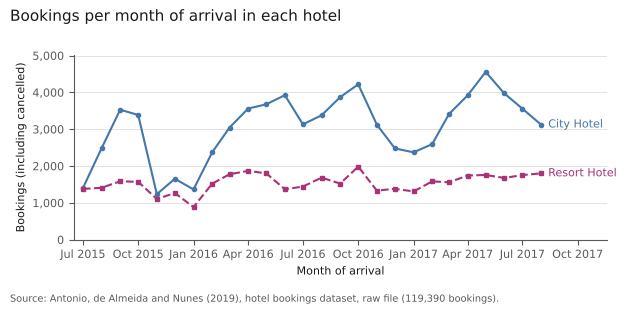

Smallest monthly gap (City - Resort): 20 in July 2015


hotel,City Hotel,Resort Hotel
min,1235,884
idxmin,2015-11-01 00:00:00,2016-01-01 00:00:00
max,4556,1984
idxmax,2017-05-01 00:00:00,2016-10-01 00:00:00


In [11]:
# ── Chart 1: bookings per arrival month, by hotel ────────────────────────────
bookings_per_month = bookings.groupby(['arrival_month_start', 'hotel']).size().unstack()

fig, ax = plt.subplots(figsize=(FIG_WIDTH, 3.0))
for hotel in ['City Hotel', 'Resort Hotel']:
    ax.plot(bookings_per_month.index, bookings_per_month[hotel], markersize=3, linewidth=1.5, **HOTEL_STYLE[hotel])
    ax.text(bookings_per_month.index[-1] + pd.Timedelta(days=12), bookings_per_month[hotel].iloc[-1], hotel,
            va='center', fontsize=8, color=HOTEL_STYLE[hotel]['color'])

ax.set_ylim(0, bookings_per_month.values.max() * 1.1)
ax.set_xlim(bookings_per_month.index[0] - pd.Timedelta(days=15), bookings_per_month.index[-1] + pd.Timedelta(days=110))
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.set_xlabel('Month of arrival')
ax.set_ylabel('Bookings (including cancelled)')
ax.yaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter('{x:,.0f}'))
clean_axes(ax, 'y')
finish_figure(fig, 'Bookings per month of arrival in each hotel', 'eda_bookings_over_time.png')
plt.show()

# Smallest gap between the hotels, and lowest and highest month of each hotel
gap = bookings_per_month['City Hotel'] - bookings_per_month['Resort Hotel']
print('Smallest monthly gap (City - Resort):', int(gap.min()), 'in', gap.idxmin().strftime('%B %Y'))
bookings_per_month.agg(['min', 'idxmin', 'max', 'idxmax'])

**Comment:** the City Hotel receives more bookings than the Resort Hotel in every month; the gap is smallest in the first month, July 2015 (20 bookings). Both hotels have a yearly rhythm, with their lowest months in winter (November 2015 for the City Hotel, January 2016 for the Resort Hotel), but the City Hotel's curve rises much more over the period, from 1,235 to 4,556 bookings per month. The series covers 26 months and only 2016 is a complete year, so totals per year cannot be compared (task 1.5).

### Chart 2: price and season

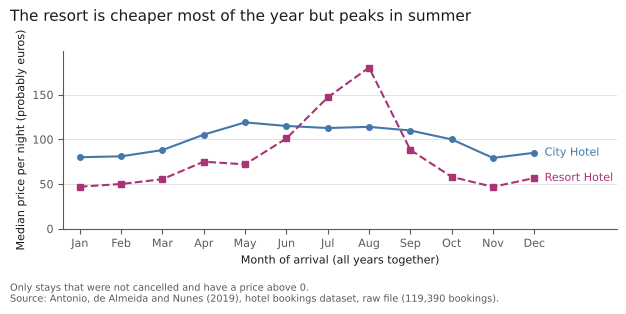

hotel,City Hotel,Resort Hotel
min,79.2,46.8
idxmin,11.0,11.0
max,119.0,180.4
idxmax,5.0,8.0


In [12]:
# ── Chart 2: median price per night by month of the year, by hotel ───────────
month_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

fig, ax = plt.subplots(figsize=(FIG_WIDTH, 3.0))
for hotel in ['City Hotel', 'Resort Hotel']:
    ax.plot(median_adr_by_month.index, median_adr_by_month[hotel], markersize=4, linewidth=1.5, **HOTEL_STYLE[hotel])
    ax.text(12.25, median_adr_by_month[hotel].iloc[-1], hotel, va='center', fontsize=8, color=HOTEL_STYLE[hotel]['color'])

ax.set_xticks(range(1, 13), month_labels)
ax.set_xlim(0.6, 14)
ax.set_ylim(0, median_adr_by_month.values.max() * 1.1)
ax.set_xlabel('Month of arrival (all years together)')
ax.set_ylabel('Median price per night (probably euros)')
clean_axes(ax, 'y')
finish_figure(fig, 'The resort is cheaper most of the year but peaks in summer', 'eda_price_by_month.png',
              note='Only stays that were not cancelled and have a price above 0.')
plt.show()

median_adr_by_month.agg(['min', 'idxmin', 'max', 'idxmax'])

**Comment:** price follows the season, but very differently in each hotel. The Resort Hotel (Algarve) is cheaper than the City Hotel from September to June, and in August its median price (180.4) is almost four times its November low (46.8), above the City Hotel. The City Hotel (Lisbon) is more stable, between 79.2 in November and 119.0 in May. This confirms the season effect suspected in task 1.3 and shows that a single average price per hotel would hide the main pattern.

### Chart 3: what goes with cancelling

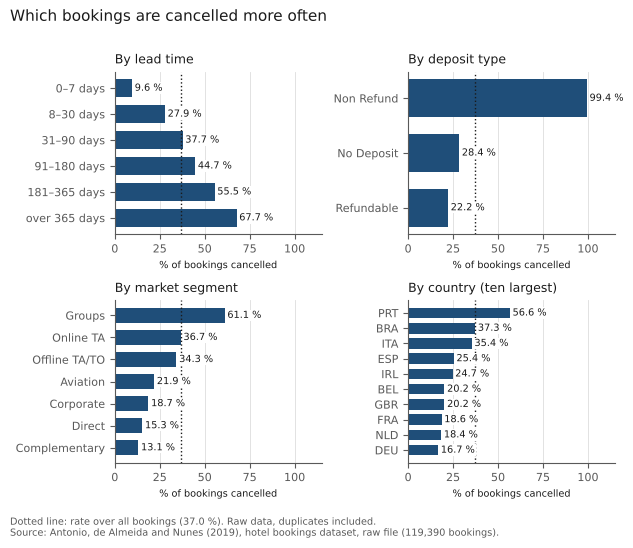

In [13]:
# ── Chart 3: cancellation rate by four fields (small multiples) ──────────────
fig, axes = plt.subplots(2, 2, figsize=(FIG_WIDTH, 5.4))
rate_bars(axes[0, 0], cancel_by_lead_time.iloc[::-1], 'By lead time', OVERALL_CANCEL_RATE)
rate_bars(axes[0, 1], cancel_by_deposit, 'By deposit type', OVERALL_CANCEL_RATE)
rate_bars(axes[1, 0], cancel_by_segment, 'By market segment', OVERALL_CANCEL_RATE)
rate_bars(axes[1, 1], cancel_by_country, 'By country (ten largest)', OVERALL_CANCEL_RATE)
finish_figure(fig, 'Which bookings are cancelled more often', 'eda_cancellation_rates.png',
              note=f'Dotted line: rate over all bookings ({OVERALL_CANCEL_RATE:.1f} %). Raw data, duplicates included.')
plt.show()

**Comment:** the clearest relationship is with **lead time**: the further ahead a booking is made, the more often it is cancelled, from 9.6 % for the last week to 67.7 % for more than a year. By segment, **Groups** are cancelled most (61.1 %) and direct and corporate bookings least. Two results need care: the 99.4 % of `Non Refund` and the 56.6 % of **Portugal** are linked to the duplicated non-refundable blocks discussed above. All four panels share the same 0–100 % scale, so their bars can be compared directly.

### Chart 4: market mix of each hotel

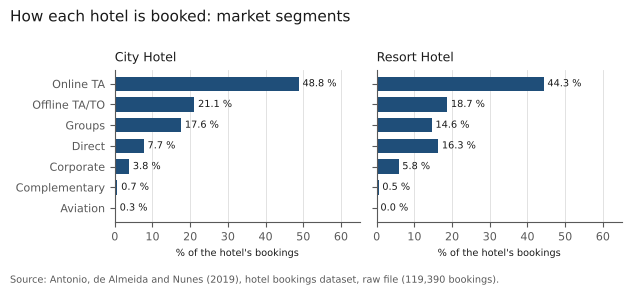

In [14]:
# ── Chart 4: market segment share, one panel per hotel ───────────────────────
fig, axes = plt.subplots(1, 2, figsize=(FIG_WIDTH, 2.8), sharey=True)
for ax, hotel in zip(axes, ['City Hotel', 'Resort Hotel']):
    shares = segment_share_by_hotel[hotel]
    ax.barh(shares.index, shares.values, color=BAR_COLOR, height=0.7)
    for position, value in enumerate(shares.values):
        ax.text(value + 1, position, f'{value:.1f} %', va='center', fontsize=7)
    ax.set_title(hotel, loc='left', fontsize=9)
    ax.set_xlim(0, 65)
    ax.set_xlabel('% of the hotel\'s bookings', fontsize=7)
    clean_axes(ax, 'x')
finish_figure(fig, 'How each hotel is booked: market segments', 'eda_segments_by_hotel.png')
plt.show()

**Comment:** the two hotels have a similar mix, led by online travel agents (48.8 % in the City Hotel, 44.3 % in the Resort Hotel). The main difference is that the Resort Hotel gets twice the share of **Direct** bookings (16.3 % against 7.7 %). Two panels with the same scale (small multiples) are used instead of coloured side-by-side bars, so each hotel is compared by position and no colour legend is needed.

### Chart 5: correlation between numeric fields

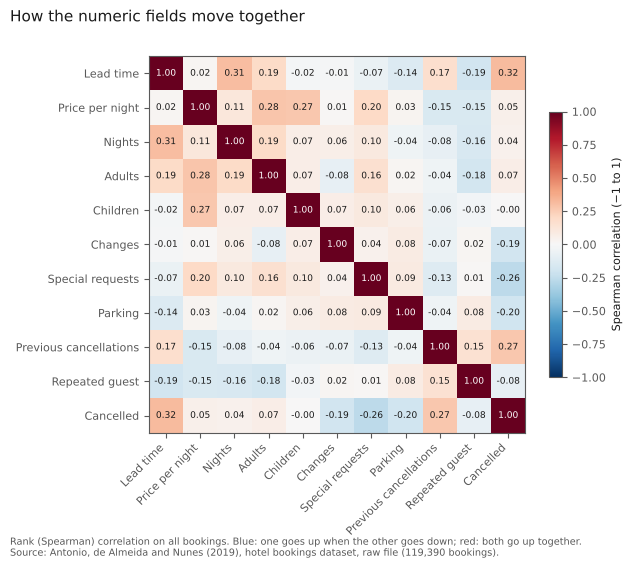

Lead time               Cancelled    0.32
                        Nights       0.31
Price per night         Adults       0.28
                        Children     0.27
Previous cancellations  Cancelled    0.27
Special requests        Cancelled   -0.26
dtype: float64

In [15]:
# ── Chart 5: Spearman correlation matrix with the values written ─────────────
fig, ax = plt.subplots(figsize=(FIG_WIDTH, 5.6))
image = ax.imshow(correlations.values, cmap='RdBu_r', vmin=-1, vmax=1)
labels = list(correlations.columns)
ax.set_xticks(range(len(labels)), labels, rotation=45, ha='right')
ax.set_yticks(range(len(labels)), labels)

# Every value is written in its cell, so the colour is never the only code;
# white text on dark cells and dark text on light cells keeps the contrast
for row in range(len(labels)):
    for column in range(len(labels)):
        value = correlations.iloc[row, column]
        ax.text(column, row, f'{value:.2f}', ha='center', va='center', fontsize=6.5,
                color='white' if abs(value) > 0.6 else TEXT_COLOR)

colour_bar = fig.colorbar(image, ax=ax, shrink=0.7)
colour_bar.set_label('Spearman correlation (−1 to 1)')
finish_figure(fig, 'How the numeric fields move together', 'eda_correlations.png',
              note='Rank (Spearman) correlation on all bookings. Blue: one goes up when the other goes down; red: both go up together.')
plt.show()

# Strongest pairs (each pair once, the diagonal left out)
pairs = correlations.where(~pd.DataFrame(
    [[r >= c for c in range(len(labels))] for r in range(len(labels))], index=labels, columns=labels)).stack()
pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(6)

**Comment:** all correlations are weak (none is above 0.32 in absolute value), so no numeric field predicts another well. The strongest links with cancelling are **lead time** (0.32) and previous cancellations (0.27), in the same direction, and special requests (−0.26) and parking (−0.20) in the opposite direction: guests who ask for something specific cancel less. Price goes up with the number of adults (0.28) and children (0.27), as expected for room prices, and longer lead times go with longer stays (0.31).

## 6. Export

In [16]:
# ── Export ────────────────────────────────────────────────────────────────────
cancel_by_hotel.to_csv(OUTPUT_DIR / 'cancel_rate_by_hotel_with_without_duplicates.csv')
pd.concat({'lead time': cancel_by_lead_time, 'deposit': cancel_by_deposit, 'segment': cancel_by_segment,
           'country': cancel_by_country}).rename('% cancelled').to_csv(OUTPUT_DIR / 'cancel_rates.csv')
bookings_per_month.to_csv(OUTPUT_DIR / 'bookings_per_month.csv')
median_adr_by_month.to_csv(OUTPUT_DIR / 'median_adr_by_month.csv')
segment_share_by_hotel.to_csv(OUTPUT_DIR / 'segment_share_by_hotel.csv')
segment_by_channel.to_csv(OUTPUT_DIR / 'segment_by_channel.csv')
correlations.to_csv(OUTPUT_DIR / 'spearman_correlations.csv')

sorted(p.name for p in OUTPUT_DIR.iterdir())

['bookings_per_month.csv',
 'cancel_rate_by_hotel_with_without_duplicates.csv',
 'cancel_rates.csv',
 'median_adr_by_month.csv',
 'segment_by_channel.csv',
 'segment_share_by_hotel.csv',
 'spearman_correlations.csv']

## Conclusions

### Main findings
1. **Time and season:** both hotels have a yearly cycle of bookings, and price follows the season very differently: the resort peaks strongly in July–August, the city hotel is more stable.
2. **Cancellations** (37.0 % of all bookings) go with long lead times, group bookings and the City Hotel. The 99.4 % cancellation of `Non Refund` deposits and Portugal's 56.6 % are tied to duplicated blocks of rooms, so they are probably a recording effect rather than guest behaviour.
3. **Duplicates change the message:** without them the cancellation rate falls from 37.0 % to 27.5 % (City Hotel 41.7 % → 30.0 %), so the cleaning decision of task 1.6 matters for the dashboard.
4. **Market mix:** both hotels depend on online travel agents; the resort has twice the share of direct bookings.
5. **Groupings:** the fields fall into stay, guests, booking process and outcome; `market_segment` makes `distribution_channel` largely redundant, and `reservation_status` contains `is_canceled`.

### Limitations
- All rates use the raw data; correlations are not causes.
- Months from different years are pooled in the price chart.

### Suggested next steps
- Task 1.5: currency and update frequency of the data.
- Task 1.6: the duplicate rule, now known to change the cancellation rate by almost ten points.